# DES asteroid taxonomy (Carruba et al. 2023) vs our mvroc objects

PDS bundle `gbo.ast.des.taxonomy_V1_0` (Small Bodies Node, 2024): Dark Energy Survey colours of main-belt asteroids
and machine-learning taxonomic labels at the **complex** level (C, S, V).
Reference: Carruba, V., Camargo, J. I. B., et al. 2023, MNRAS 527, 6495, *Main belt asteroids taxonomical
information from Dark Energy Survey data*, doi:10.1093/mnras/stad3466.

Files in `data/gbo.ast.des.taxonomy_V1_0/data/` (columns from the PDS labels, the CSVs have no header):

| file | rows | columns | label |
|---|---|---|---|
| `des_gri_iz.csv` | 16517 | row, id, gri slope [%/100nm], err, i−z, err, label | 0 = C-complex, 1 = S-complex, 2 = V-type |
| `des_gr_gi.csv` | 58116 | row, id, g−r, err, g−i, err, label | 0 = C-complex, 1 = S-complex |
| `v_types_pred.csv` | 409 | id, proper a [au], e, sin i, H | new V-type candidates |

`id` is the asteroid number when it exists, otherwise the provisional designation **without the space**
(`2007DK31`). Rows were kept when the gri-slope error < 10 %/100nm and colour errors < 0.1 mag.

Plan: (1) explore the three tables, (2) cross-match them with `mvroc (1).csv`, (3) compare the colours,
(4) compare the gri slopes, (5) compare the classes.

In [13]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import taxonomy as tx

DES_DIR = 'data/gbo.ast.des.taxonomy_V1_0/data'
MVROC = 'data/mvroc (1).csv'
FIG_DIR = 'figures/des_comparison'
os.makedirs(FIG_DIR, exist_ok=True)

if not os.path.isdir(DES_DIR):   # unzip the PDS bundle the first time
    import zipfile
    zipfile.ZipFile('data/gbo.ast.des.taxonomy_V1_0.zip').extractall('data')

des_sl = pd.read_csv(f'{DES_DIR}/des_gri_iz.csv', header=None, dtype={1: str},
                     names=['row', 'id', 'gri', 'gri_err', 'iz', 'iz_err', 'label'])
des_col = pd.read_csv(f'{DES_DIR}/des_gr_gi.csv', header=None, dtype={1: str},
                      names=['row', 'id', 'gr', 'gr_err', 'gi', 'gi_err', 'label'])
des_v = pd.read_csv(f'{DES_DIR}/v_types_pred.csv', header=None, dtype={0: str},
                    names=['id', 'a', 'e', 'sin_i', 'H'])

LABELS = {0: 'C', 1: 'S', 2: 'V'}
for d in (des_sl, des_col):
    d['complex'] = d['label'].map(LABELS)

for name, d in [('des_gri_iz', des_sl), ('des_gr_gi', des_col), ('v_types_pred', des_v)]:
    numbered = d['id'].str.fullmatch(r'\d+').mean()
    print(f"{name:13s}: {len(d):6d} rows, {d['id'].nunique():6d} ids, {numbered:.0%} numbered")
print(f"\nin both DES colour tables: {len(set(des_sl['id']) & set(des_col['id']))};  "
      f"V candidates in des_gri_iz: {des_v['id'].isin(des_sl['id']).sum()}")

des_gri_iz   :  16517 rows,  16517 ids, 62% numbered
des_gr_gi    :  58116 rows,  58116 ids, 61% numbered
v_types_pred :    409 rows,    409 ids, 99% numbered

in both DES colour tables: 15521;  V candidates in des_gri_iz: 409


## 1. Exploration of the DES tables

In [14]:
summary = pd.concat({
    'des_gri_iz': des_sl['complex'].value_counts(),
    'des_gr_gi': des_col['complex'].value_counts(),
}, axis=1).fillna(0).astype(int)
display(summary)
display(des_sl.groupby('complex')[['gri', 'gri_err', 'iz', 'iz_err']].median().round(3))
display(des_col.groupby('complex')[['gr', 'gr_err', 'gi', 'gi_err']].median().round(3))

,des_gri_iz,des_gr_gi
complex,,
C,10213,28871
S,5891,29245
V,413,0


,gri,gri_err,iz,iz_err
complex,,,,
C,2.074,1.288,0.046,0.043
S,9.184,2.784,-0.021,0.039
V,6.979,4.844,-0.286,0.040


,gr,gr_err,gi,gi_err
complex,,,,
C,0.479,0.025,0.611,0.045
S,0.651,0.025,0.815,0.042


Left: DES gri slope vs i−z coloured by the DES label, on our taxonomy boxes (`tx.plot_taxonomy`).
Right: g−r vs g−i coloured by the DES label.

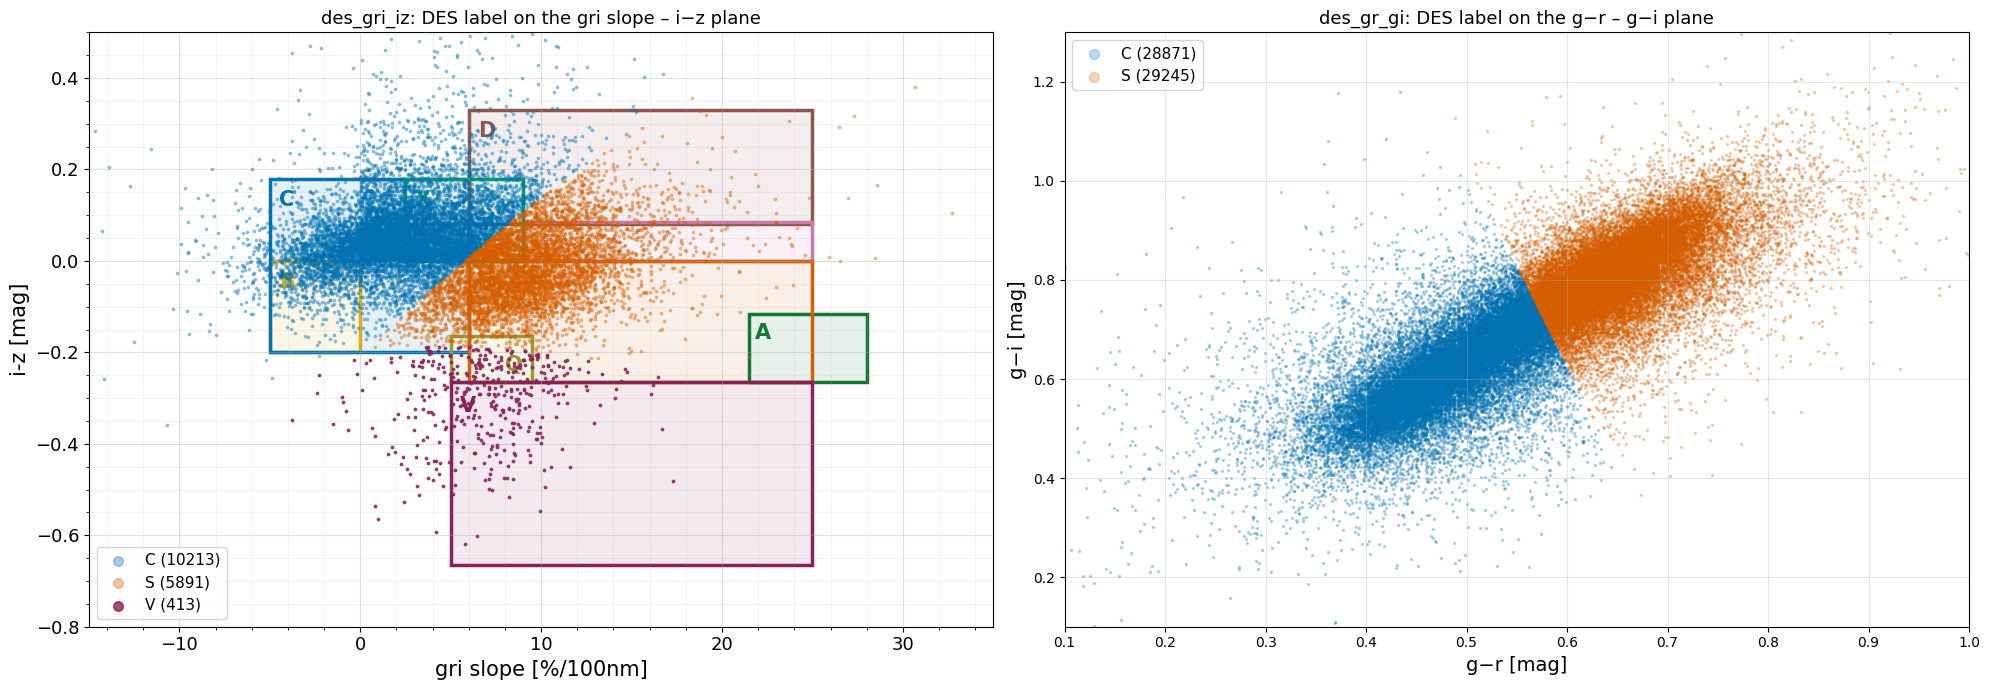

In [15]:
CPLX_COLORS = {'C': tx.PAL['C'], 'S': tx.PAL['S'], 'V': tx.PAL['V']}

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
ax = axes[0]
tx.plot_taxonomy([], ax=ax, legend=False, region_alpha=0.10)
for c in ['C', 'S', 'V']:
    g = des_sl[des_sl['complex'] == c]
    ax.scatter(g['gri'], g['iz'], s=3, color=CPLX_COLORS[c], alpha=0.35 if c != 'V' else 0.8,
               label=f'{c} ({len(g)})', zorder=3)
ax.set_xlim(-15, 35)
ax.set_ylim(-0.8, 0.5)
ax.set_title('des_gri_iz: DES label on the gri slope – i−z plane', fontsize=13)
ax.legend(loc='lower left', fontsize=11, markerscale=4)

ax = axes[1]
for c in ['C', 'S']:
    g = des_col[des_col['complex'] == c]
    ax.scatter(g['gr'], g['gi'], s=2, color=CPLX_COLORS[c], alpha=0.25, label=f'{c} ({len(g)})')
ax.set_xlabel('g−r [mag]', fontsize=14)
ax.set_ylabel('g−i [mag]', fontsize=14)
ax.set_xlim(0.1, 1.0)
ax.set_ylim(0.1, 1.3)
ax.grid(alpha=0.3)
ax.set_title('des_gr_gi: DES label on the g−r – g−i plane', fontsize=13)
ax.legend(loc='upper left', fontsize=11, markerscale=5)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'des_overview.png'), dpi=130)
plt.show()

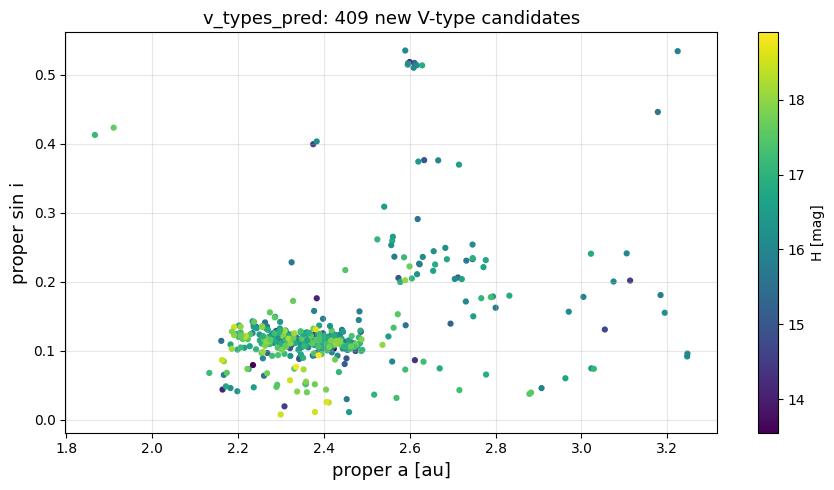

In [16]:
# the 409 new V-type candidates: proper elements
fig, ax = plt.subplots(figsize=(9, 5))
sc = ax.scatter(des_v['a'], des_v['sin_i'], c=des_v['H'], s=12, cmap='viridis')
fig.colorbar(sc, ax=ax, label='H [mag]')
ax.set_xlabel('proper a [au]', fontsize=13)
ax.set_ylabel('proper sin i', fontsize=13)
ax.set_title(f'v_types_pred: {len(des_v)} new V-type candidates', fontsize=13)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'des_v_types.png'), dpi=130)
plt.show()

## 2. Cross-match with mvroc

A mvroc solution is matched by its number (`permid`) or, if it has no number in DES, by `provid` without the
space. mvroc has one row per solution, so an object can appear more than once.

In [17]:
mv = pd.read_csv(MVROC)
mv['number'] = mv['permid'].astype('Int64').astype(str)
mv['provid_nospace'] = mv['provid'].str.replace(' ', '', regex=False)
all_des_ids = set(des_sl['id']) | set(des_col['id']) | set(des_v['id'])
mv['des_id'] = np.where(mv['number'].isin(all_des_ids), mv['number'], mv['provid_nospace'])
mv['g-i'] = mv['g-r'] + mv['r-i']
mv['g-i_err'] = np.hypot(mv['g-r_err'], mv['r-i_err'])   # upper bound: g-r and r-i share r

xm = pd.DataFrame({
    'in des_gri_iz': mv.groupby('provid')['des_id'].first().isin(des_sl['id']),
    'in des_gr_gi': mv.groupby('provid')['des_id'].first().isin(des_col['id']),
    'in v_types_pred': mv.groupby('provid')['des_id'].first().isin(des_v['id']),
})
print(f"mvroc: {len(mv)} solutions of {mv['provid'].nunique()} objects")
print(xm.sum().to_string())
print(f"in any DES table: {xm.any(axis=1).sum()} objects")
has3 = mv[mv[['g-r', 'r-i', 'i-z']].notna().all(axis=1)]['provid'].unique()
print(f"of them with g-r, r-i and i-z in mvroc (our box classification): {xm.loc[xm.index.isin(has3)].any(axis=1).sum()}")

mvroc: 1092 solutions of 703 objects
in des_gri_iz      13
in des_gr_gi       45
in v_types_pred     0
in any DES table: 47 objects
of them with g-r, r-i and i-z in mvroc (our box classification): 4


## 3. Colours: mvroc vs DES (`des_gr_gi`)

Every matched solution with g−r and r−i. g−i = (g−r) + (r−i). The two catalogues come from different surveys and
photometric systems (mvroc vs DECam) and from different epochs, so a small offset is expected.

45 objects, 64 solutions
d_gr: median -0.042, robust std 0.036 mag
d_gi: median -0.028, robust std 0.067 mag


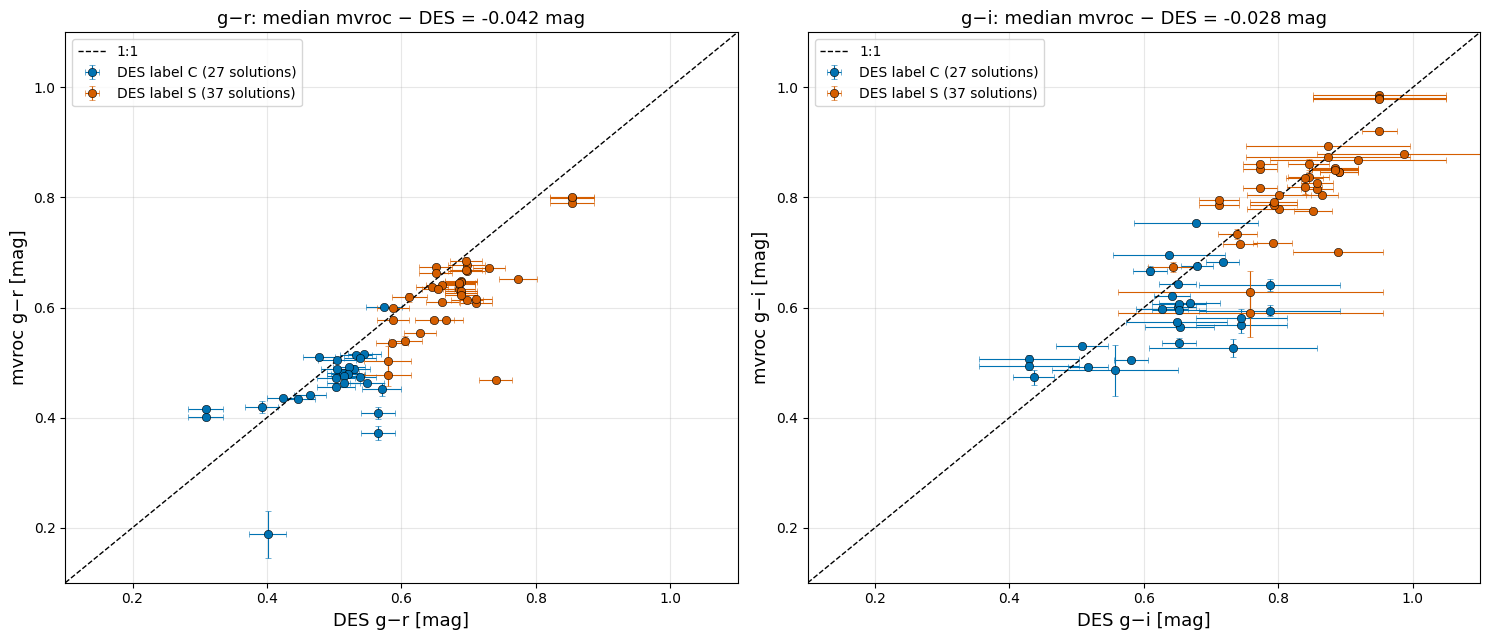

In [18]:
m_col = mv.merge(des_col, left_on='des_id', right_on='id')
m_col = m_col[m_col[['g-r', 'r-i']].notna().all(axis=1)].reset_index(drop=True)
m_col['d_gr'] = m_col['g-r'] - m_col['gr']
m_col['d_gi'] = m_col['g-i'] - m_col['gi']
print(f"{m_col['provid'].nunique()} objects, {len(m_col)} solutions")
for c in ['d_gr', 'd_gi']:
    print(f"{c}: median {m_col[c].median():+.3f}, robust std {1.4826 * (m_col[c] - m_col[c].median()).abs().median():.3f} mag")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
for ax, (ours, des, lbl) in zip(axes, [('g-r', 'gr', 'g−r'), ('g-i', 'gi', 'g−i')]):
    for c in ['C', 'S']:
        g = m_col[m_col['complex'] == c]
        ax.errorbar(g[des], g[ours], xerr=g[f'{des}_err'], yerr=g[f'{ours}_err'], fmt='o', ms=6,
                    color=CPLX_COLORS[c], mec='k', mew=0.4, elinewidth=0.8, capsize=2.5,
                    label=f'DES label {c} ({len(g)} solutions)')
    lo, hi = 0.1, 1.1
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, label='1:1')
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel(f'DES {lbl} [mag]', fontsize=13)
    ax.set_ylabel(f'mvroc {lbl} [mag]', fontsize=13)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=10)
    ax.set_title(f"{lbl}: median mvroc − DES = {m_col['d_' + des[0] + des[1:]].median():+.3f} mag", fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'colours_mvroc_vs_des.png'), dpi=130)
plt.show()

## 4. gri slope: mvroc vs DES (`des_gri_iz`)

Our slope for every matched solution with g−r and r−i (i−z is not needed for the slope), three ways:

* **Carruba formula, SDSS** (section 1 of `taxonomies_classification`): $S = 10^4 (R_r - R_i)/|\lambda_i - \lambda_r|$.
* **Unweighted linear fit, LSST** (`tx.gri_slope_fit_colors`).
* **Weighted linear fit, LSST** (`tx.gri_slope_fit`, section 2): per-band errors from the colour errors as in
  section 2; when i−z is missing, $\sigma_i^2 = \sigma_{r-i}^2/2$.

In [19]:
def band_errors(s):
    v_gr, v_ri, v_iz = s['g-r_err'] ** 2, s['r-i_err'] ** 2, s['i-z_err'] ** 2
    sig_i = np.where(np.isfinite(v_iz), np.sqrt((v_ri + v_iz) / 4), np.sqrt(v_ri / 2))
    return np.sqrt(v_gr / 2), np.sqrt((v_gr + v_ri) / 4), sig_i


m_sl = mv.merge(des_sl, left_on='des_id', right_on='id')
m_sl = m_sl[m_sl[['g-r', 'r-i']].notna().all(axis=1)].reset_index(drop=True)
m_sl['S_carruba_sdss'] = tx.gri_slope_carruba(m_sl['g-r'], m_sl['r-i'])
m_sl['S_fit_lsst'] = tx.gri_slope_fit_colors(m_sl['g-r'], m_sl['r-i'])
sg, sr, si = band_errors(m_sl)
R = tx.gri_reflectances(0 * m_sl['g-r'], -m_sl['g-r'], -m_sl['g-i'], sg, sr, si, m_sun=tx.M_SUN_LSST)
fit = tx.gri_slope_fit(R[['R_g', 'R_r', 'R_i']], R[['R_g_err', 'R_r_err', 'R_i_err']], lam=tx.LAM_LSST)
m_sl['S_curvefit_lsst'] = fit['slope']
m_sl['S_curvefit_lsst_err'] = fit['slope_err']

SLOPES = {'S_carruba_sdss': 'Carruba formula, SDSS', 'S_fit_lsst': 'unweighted fit, LSST',
          'S_curvefit_lsst': 'weighted fit (curve_fit), LSST'}
print(f"{m_sl['provid'].nunique()} objects, {len(m_sl)} solutions")
for c, lbl in SLOPES.items():
    r = np.corrcoef(m_sl[c], m_sl['gri'])[0, 1]
    print(f"{lbl:32s}: median ours − DES = {(m_sl[c] - m_sl['gri']).median():+6.2f} %/100nm, correlation {r:+.2f}")
m_sl[['provid', 'solution_id', 'des_id', 'gri', 'gri_err', 'complex'] + list(SLOPES) + ['i-z', 'iz']].round(3)

13 objects, 20 solutions
Carruba formula, SDSS           : median ours − DES =  +1.84 %/100nm, correlation -0.27
unweighted fit, LSST            : median ours − DES =  +0.79 %/100nm, correlation +0.93
weighted fit (curve_fit), LSST  : median ours − DES =  +1.26 %/100nm, correlation +0.92


,provid,solution_id,des_id,gri,gri_err,complex,S_carruba_sdss,S_fit_lsst,S_curvefit_lsst,i-z,iz
0,2000 GX87,1,30180,11.267,3.311,S,7.272,14.497,14.914,NaN,-0.034
1,2000 GX87,2,30180,11.267,3.311,S,9.155,13.609,13.786,NaN,-0.034
2,2000 SQ35,1,118799,8.489,5.813,S,9.559,10.351,11.046,NaN,-0.059
3,2001 QT132,1,55097,6.385,0.931,C,9.014,7.140,7.178,NaN,0.098
4,2001 QT132,2,55097,6.385,0.931,C,9.263,6.642,6.808,NaN,0.098
5,2001 UE225,1,344324,-2.027,0.120,C,13.711,-1.206,-1.138,NaN,0.132
6,2001 UG126,1,176396,14.866,9.249,S,10.912,19.065,21.167,NaN,-0.104
7,2001 UG126,2,176396,14.866,9.249,S,10.535,18.806,21.335,NaN,-0.104
8,2001 UG126,3,176396,14.866,9.249,S,11.462,18.757,20.786,NaN,-0.104
9,2002 DE21,1,2002DE21,2.555,NaN,C,15.004,1.243,2.186,NaN,0.027


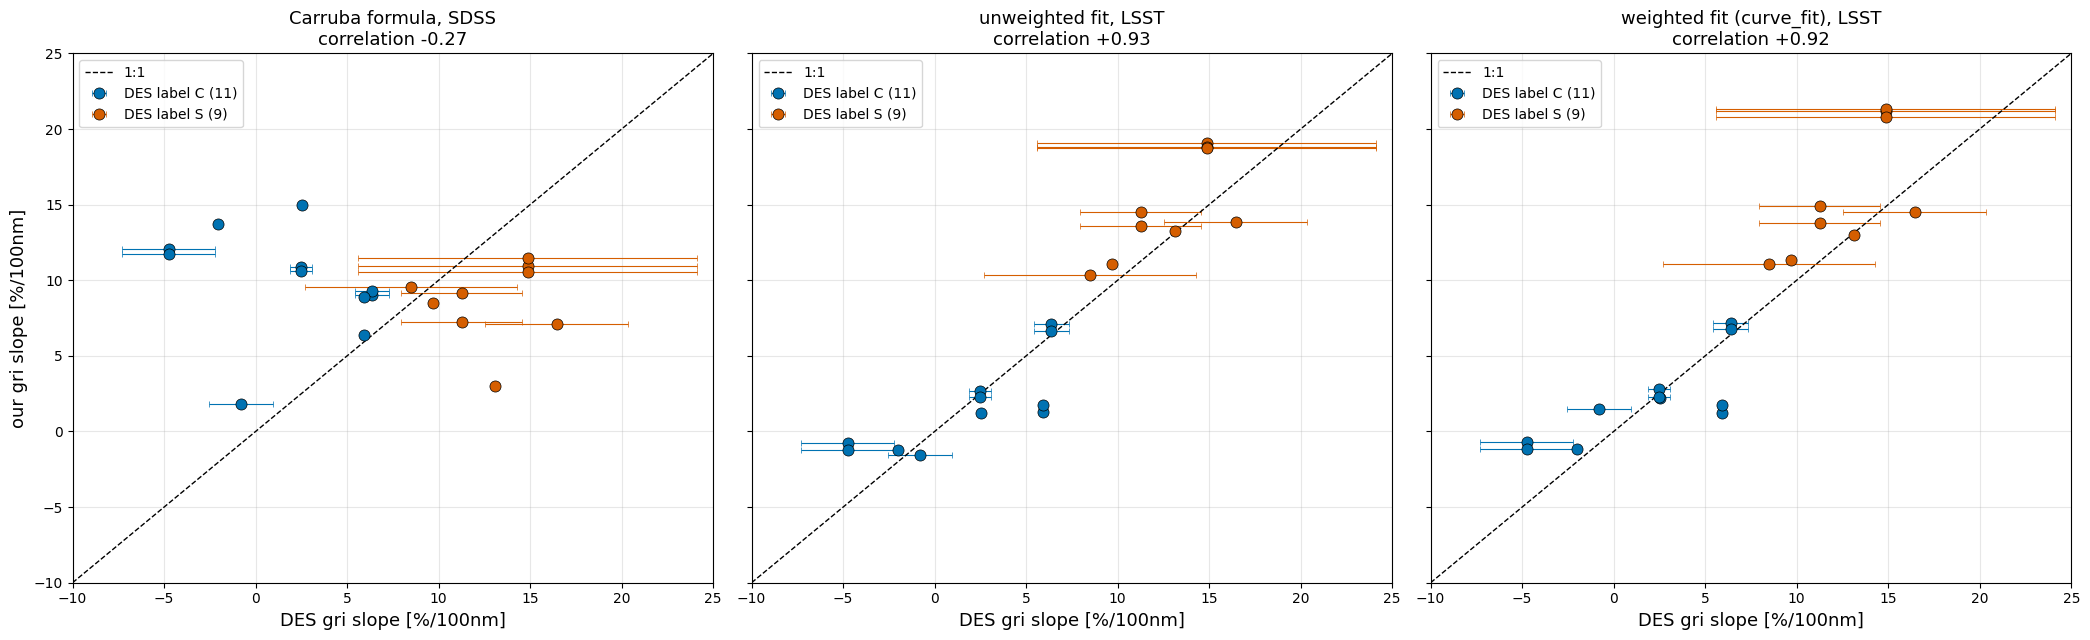

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5), sharey=True)
for ax, (c, lbl) in zip(axes, SLOPES.items()):
    for cp in ['C', 'S', 'V']:
        g = m_sl[m_sl['complex'] == cp]
        if len(g):
            ax.errorbar(g['gri'], g[c], xerr=g['gri_err'], fmt='o', ms=8, color=CPLX_COLORS[cp], mec='k',
                        mew=0.5, elinewidth=0.8, capsize=2.5, label=f'DES label {cp} ({len(g)})')
    ax.plot([-10, 25], [-10, 25], 'k--', lw=1, label='1:1')
    ax.set_xlim(-10, 25)
    ax.set_ylim(-10, 25)
    ax.set_xlabel('DES gri slope [%/100nm]', fontsize=13)
    ax.set_title(f"{lbl}\ncorrelation {np.corrcoef(m_sl[c], m_sl['gri'])[0, 1]:+.2f}", fontsize=13)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=10, loc='upper left')
axes[0].set_ylabel('our gri slope [%/100nm]', fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'gri_slope_mvroc_vs_des.png'), dpi=130)
plt.show()

## 5. Classes: mvroc vs DES labels

DES labels are complexes (C, S, V), while our boxes give classes. Mapping used here (an assumption):
**C-complex** ← B, C; **S-complex** ← S, Q, A, L; **V** ← V. X and D have no DES counterpart and are reported as
they are.

**5a. C/S from g−r and g−i (all matched objects).** Our box classification needs i−z, which only a few matched
objects have, so we also train a classifier on the DES labels in the g−r – g−i plane (k nearest neighbours,
all 58116 DES objects) and apply it to the mvroc colours. This tells us whether our colours put the object on
the same side as DES. The colour offset of section 3 is not removed.

**5b. Our box classes** (weighted fit, LSST, as in section 2) for the matched solutions that have i−z.

In [21]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

X_des = des_col[['gr', 'gi']].to_numpy()
y_des = des_col['complex'].to_numpy()
knn = KNeighborsClassifier(n_neighbors=25)
cv = cross_val_score(knn, X_des, y_des, cv=5)
knn.fit(X_des, y_des)
print(f"kNN on the DES labels (g-r, g-i), 5-fold accuracy: {cv.mean():.3f} ± {cv.std():.3f}")

m_col['complex_knn'] = knn.predict(m_col[['g-r', 'g-i']].to_numpy())
m_col['p_S_knn'] = knn.predict_proba(m_col[['g-r', 'g-i']].to_numpy())[:, list(knn.classes_).index('S')]
m_col['agree_knn'] = np.where(m_col['complex_knn'] == m_col['complex'], 'yes', 'no')
print(f"mvroc colours vs DES label: {(m_col['agree_knn'] == 'yes').sum()} of {len(m_col)} solutions agree")
print(pd.crosstab(m_col['complex'], m_col['complex_knn'], rownames=['DES label'], colnames=['kNN on mvroc colours']))

kNN on the DES labels (g-r, g-i), 5-fold accuracy: 0.999 ± 0.001
mvroc colours vs DES label: 57 of 64 solutions agree
kNN on mvroc colours   C   S
DES label                   
C                     26   1
S                      6  31


In [22]:
COMPLEX = {'B': 'C', 'C': 'C', 'S': 'S', 'Q': 'S', 'A': 'S', 'L': 'S', 'V': 'V', 'X': 'X', 'D': 'D'}

m_all = mv.merge(pd.concat([des_col[['id', 'complex']], des_sl[['id', 'complex']]]).drop_duplicates('id'),
                 left_on='des_id', right_on='id')
m_box = m_all[m_all[['g-r', 'r-i', 'i-z']].notna().all(axis=1)].reset_index(drop=True)
sg, sr, si = band_errors(m_box)
R = tx.gri_reflectances(0 * m_box['g-r'], -m_box['g-r'], -m_box['g-i'], sg, sr, si, m_sun=tx.M_SUN_LSST)
fit = tx.gri_slope_fit(R[['R_g', 'R_r', 'R_i']], R[['R_g_err', 'R_r_err', 'R_i_err']], lam=tx.LAM_LSST)
m_box['slope_lsst'], m_box['slope_lsst_err'] = fit['slope'], fit['slope_err']
res = tx.classify_catalogue(m_box['slope_lsst'], m_box['i-z'], m_box['slope_lsst_err'], m_box['i-z_err'])
m_box['taxonomy'] = res['taxonomy']
m_box['candidates'] = res['candidates']
m_box['our_complex'] = m_box['taxonomy'].map(COMPLEX).fillna(m_box['taxonomy'])
m_box['agree'] = np.where(m_box['our_complex'] == m_box['complex'], 'yes', 'no')
print(f"{m_box['provid'].nunique()} objects / {len(m_box)} solutions with i-z")
m_box[['provid', 'solution_id', 'des_id', 'slope_lsst', 'slope_lsst_err', 'i-z', 'taxonomy', 'candidates',
       'our_complex', 'complex', 'agree']].rename(columns={'complex': 'DES label'}).round(3)

4 objects / 5 solutions with i-z


,provid,solution_id,des_id,slope_lsst,slope_lsst_err,i-z,taxonomy,candidates,our_complex,DES label,agree
0,2000 YE107,1,42048,-0.418,0.210,-0.019,B,B 0.86 / C 0.14,C,C,yes
1,2003 QT52,1,244712,7.298,0.226,-0.056,S,S 1.00,S,S,yes
2,2008 VQ79,1,418825,1.495,1.049,-0.138,C,C 0.91 / B 0.08,C,C,yes
3,2013 BM30,1,2013BM30,5.173,1.738,0.212,indeterminate,X 0.30 / D 0.11 / C 0.08,indeterminate,S,no
4,2013 BM30,3,2013BM30,4.380,1.466,0.446,unclassified,,unclassified,S,no


### Summary figure

DES objects in the background (small dots, C blue and S orange) and the matched mvroc solutions on top
(stars, coloured by their DES label), with a line to the DES colours of the same object. Green squares: the solutions with i−z that we
classified with our boxes (5b), labelled with our class and the DES label.

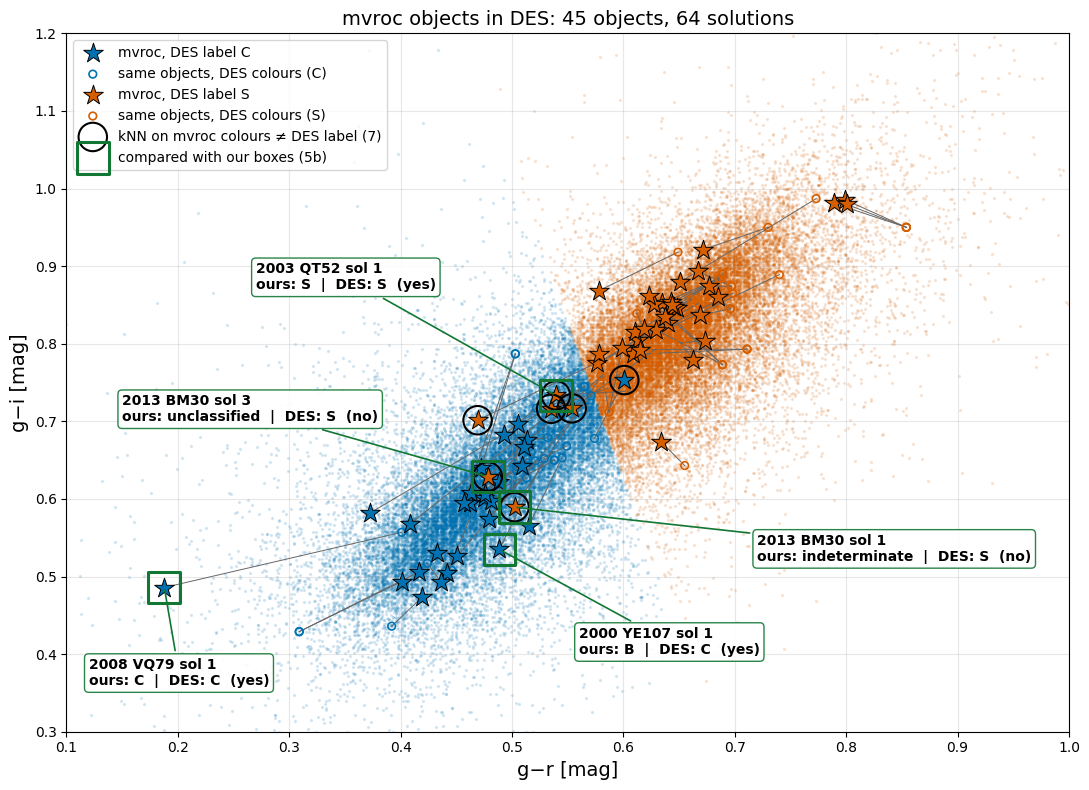

In [23]:
fig, ax = plt.subplots(figsize=(11, 8))
for c in ['C', 'S']:
    g = des_col[des_col['complex'] == c]
    ax.scatter(g['gr'], g['gi'], s=2, color=CPLX_COLORS[c], alpha=0.12, zorder=1)
for _, r in m_col.iterrows():
    ax.plot([r['gr'], r['g-r']], [r['gi'], r['g-i']], '-', color='0.4', lw=0.7, zorder=2)
for c in ['C', 'S']:
    g = m_col[m_col['complex'] == c]
    ax.scatter(g['g-r'], g['g-i'], marker='*', s=220, color=CPLX_COLORS[c], edgecolors='k', linewidths=0.7,
               zorder=4, label=f'mvroc, DES label {c}')
    ax.scatter(g['gr'], g['gi'], marker='o', s=30, facecolors='none', edgecolors=CPLX_COLORS[c], linewidths=1.2,
               zorder=3, label=f'same objects, DES colours ({c})')
bad = m_col[m_col['agree_knn'] == 'no']
ax.scatter(bad['g-r'], bad['g-i'], marker='o', s=420, facecolors='none', edgecolors='k', linewidths=1.5,
           zorder=5, label=f'kNN on mvroc colours ≠ DES label ({len(bad)})')
# the objects with i-z, compared class vs label in 5b: green square + name, our class and the DES label
# label positions (g-r, g-i) in empty parts of the plot
LABEL_XY = {('2000 YE107', 1): (0.56, 0.40), ('2003 QT52', 1): (0.27, 0.87), ('2008 VQ79', 1): (0.12, 0.36),
            ('2013 BM30', 1): (0.72, 0.52), ('2013 BM30', 3): (0.15, 0.70)}
box_pts = m_box.merge(m_col[['provid', 'solution_id', 'g-r', 'g-i']], on=['provid', 'solution_id'],
                      suffixes=('_box', ''))
for k, (_, r) in enumerate(box_pts.iterrows()):
    ax.scatter(r['g-r'], r['g-i'], marker='s', s=520, facecolors='none', edgecolors='#117733',
               linewidths=2.2, zorder=6, label='compared with our boxes (5b)' if k == 0 else None)
    ax.annotate(f"{r['provid']} sol {r['solution_id']}\nours: {r['taxonomy']}  |  DES: {r['complex']}  ({r['agree']})",
                (r['g-r'], r['g-i']), xytext=LABEL_XY.get((r['provid'], r['solution_id']), (0.75, 0.40)), textcoords='data',
                fontsize=10, fontweight='bold', ha='left',
                bbox=dict(boxstyle='round,pad=0.3', fc='white', ec='#117733', alpha=0.9),
                arrowprops=dict(arrowstyle='-', color='#117733', lw=1.2), zorder=7)
ax.set_xlim(0.1, 1.0)
ax.set_ylim(0.3, 1.2)
ax.set_xlabel('g−r [mag]', fontsize=14)
ax.set_ylabel('g−i [mag]', fontsize=14)
ax.grid(alpha=0.3)
ax.legend(fontsize=10, loc='upper left')
ax.set_title(f"mvroc objects in DES: {m_col['provid'].nunique()} objects, {len(m_col)} solutions", fontsize=14)
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, 'mvroc_in_des_gr_gi.png'), dpi=130)
plt.show()

In [24]:
out = (m_col[['provid', 'solution_id', 'des_id', 'g-r', 'g-r_err', 'g-i', 'g-i_err', 'gr', 'gr_err', 'gi', 'gi_err',
               'complex', 'complex_knn', 'p_S_knn', 'agree_knn']]
       .rename(columns={'gr': 'des_g-r', 'gr_err': 'des_g-r_err', 'gi': 'des_g-i', 'gi_err': 'des_g-i_err',
                        'complex': 'des_label'}))
out = out.merge(m_sl[['provid', 'solution_id', 'gri', 'gri_err', 'iz'] + list(SLOPES)]
                .rename(columns={'gri': 'des_gri', 'gri_err': 'des_gri_err', 'iz': 'des_i-z'}),
                on=['provid', 'solution_id'], how='outer')
out = out.merge(m_box[['provid', 'solution_id', 'i-z', 'taxonomy', 'our_complex', 'agree']],
                on=['provid', 'solution_id'], how='left')
out.to_csv(os.path.join(FIG_DIR, 'mvroc_des_crossmatch.csv'), index=False)
print(f"saved {FIG_DIR}/mvroc_des_crossmatch.csv ({len(out)} solutions, {out['provid'].nunique()} objects)")

saved figures/des_comparison/mvroc_des_crossmatch.csv (67 solutions, 47 objects)


## Findings (run of 2026-11-17)

* **Overlap is small.** 47 of the 703 mvroc objects are in DES: 45 in `des_gr_gi`, 13 in `des_gri_iz`, none
  among the 409 V-type candidates. Only 4 of them have i−z in mvroc, so our box classification can be compared
  for 4 objects only.
* **Colours agree** with a small offset: mvroc − DES = −0.04 mag in g−r and −0.03 mag in g−i (mvroc bluer).
* **gri slope:** our linear-fit slopes follow DES (correlation +0.93 unweighted, +0.92 weighted; median offset
  +0.8 and +1.3 %/100nm). The Carruba formula with SDSS parameters (section 1 of `taxonomies_classification`)
  does **not** (correlation −0.27): DES C-complex objects at −5 to +2.5 %/100nm get 9–15 %/100nm with it.
* **C/S complex from g−r, g−i:** 57 of 64 solutions fall on the same side as the DES label. The 7 differences
  are objects near the C/S boundary (g−r ≈ 0.47–0.60), where the colour offset is enough to change side.
  The DES labels follow a sharp line in this plane (the kNN reproduces them at 99.9 %), so this is a test of
  where our colours fall, not an independent classification.
* **Box classes (4 objects with i−z):** 3 agree (2000 YE107 B→C, 2003 QT52 S, 2008 VQ79 C); 2013 BM30 is S in
  DES but indeterminate / unclassified for us (i−z = 0.21 and 0.45, too red for S).